# Skin lesion screening: MobileNetV3-Large
HAM10000 dataset -> train -> evaluate -> robustness -> Grad-CAM -> INT8 ONNX.

What this notebook does:
1. Loads the dataset: It reads the HAM10000 metadata and images, labels each image melanoma (1) or non-melanoma (0), and splits them 70/15/15 into train, validation and test sets by lesion, so photos of the same lesion never appear in two sets.
2. Prepares the images: It resizes them to 224 × 224. During training it also flips, rotates, blurs, compresses (JPEG) and darkens them, to mimic poor-quality field photos.
3. Builds the model: It starts from MobileNetV3-Large pretrained on ImageNet, adds a new melanoma classifier, and fine-tunes only that classifier and the last few layers, which suits limited data.
4. Trains it: It learns from the training images, weights the rare melanoma cases more heavily, and keeps the best epoch by validation AUC.
5. Evaluates it: It sets the decision threshold on the validation data to catch about 90% of melanomas, then reports AUC, sensitivity, specificity and accuracy on the test set.
6. Tests robustness: It repeats the evaluation on blurred, heavily compressed and dark versions of the test images to show how performance drops with poor image quality.
7. Explains predictions: Grad-CAM draws a heatmap showing which parts of each image influenced the prediction.
8. Shrinks it for the Pi: It exports the model to ONNX, quantizes it to 8-bit (INT8), and compares file size and accuracy against the full-precision version. It saves the model, heatmap weights and threshold in an outputs folder for the Raspberry Pi.

In [2]:
# 1. SETUP 
import io, copy, json, random
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image, ImageFilter, ImageEnhance
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

DATA_DIR = Path(r"C:\Users\naomi\OneDrive\Desktop\Career\Projects\MacAI Project\datasets")
TRAIN_LIMIT = None      # e.g. 800 to simulate low data, None = use all training images
EPOCHS = 10
BATCH = 32
PRETRAINED = True       # ImageNet weights (needs internet the first time)
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

random.seed(42); np.random.seed(42); torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cpu


In [3]:
# 2. DATA: melanoma = 1, everything else = 0, split by lesion (70/15/15)
csv_files = list(DATA_DIR.rglob("HAM10000_metadata.csv"))
assert csv_files, f"HAM10000_metadata.csv not found under {DATA_DIR}. Download it and put it in that folder."

df = pd.read_csv(csv_files[0])
df["label"] = (df["dx"] == "mel").astype(int)
files = {p.stem: p for p in DATA_DIR.rglob("*.jpg")}
df["path"] = df["image_id"].map(files)
assert df["path"].notna().any(), f"No matching .jpg images found under {DATA_DIR}."
df = df.dropna(subset=["path"]).reset_index(drop=True)

def split(d, test_size):
    a, b = next(GroupShuffleSplit(1, test_size=test_size, random_state=42).split(d, groups=d["lesion_id"]))
    return d.iloc[a].reset_index(drop=True), d.iloc[b].reset_index(drop=True)

train_val, test_df = split(df, 0.15)
train_df, val_df = split(train_val, 0.15 / 0.85)
if TRAIN_LIMIT:
    train_df = train_df.sample(min(TRAIN_LIMIT, len(train_df)), random_state=42).reset_index(drop=True)
for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{n}: {len(d)} images, {d.label.sum()} melanoma")

train: 6959 images, 771 melanoma
val: 1529 images, 156 melanoma
test: 1527 images, 186 melanoma


In [4]:
# 3. TRANSFORMS (training adds blur, JPEG compression and low light to mimic poor photos)
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_input = [transforms.ToTensor(), transforms.Normalize(MEAN, STD)]

def jpeg(im, q):
    buf = io.BytesIO(); im.save(buf, "JPEG", quality=q); buf.seek(0)
    return Image.open(buf).convert("RGB")

train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(), transforms.RandomRotation(180),
    transforms.ColorJitter(brightness=(0.3, 1.3), contrast=0.3),
    transforms.RandomApply([transforms.GaussianBlur(9, (0.5, 3.0))], p=0.3),
    transforms.RandomApply([transforms.Lambda(lambda im: jpeg(im, random.randint(15, 80)))], p=0.3),
] + to_input)

def eval_tf(degrade=None):
    steps = [transforms.Resize((224, 224))]
    if degrade: steps.append(transforms.Lambda(degrade))
    return transforms.Compose(steps + to_input)

class DS(Dataset):
    def __init__(self, d, tf): self.d, self.tf = d, tf
    def __len__(self): return len(self.d)
    def __getitem__(self, i):
        r = self.d.iloc[i]
        return self.tf(Image.open(r["path"]).convert("RGB")), int(r["label"])

train_loader = DataLoader(DS(train_df, train_tf), batch_size=BATCH, shuffle=True)
val_loader = DataLoader(DS(val_df, eval_tf()), batch_size=BATCH)
test_loader = DataLoader(DS(test_df, eval_tf()), batch_size=BATCH)

In [6]:
# 4. MODEL + TRAINING (pretrained MobileNetV3-Large; train the new head + last 4 blocks)
model = mobilenet_v3_large(weights=MobileNet_V3_Large_Weights.DEFAULT if PRETRAINED else None)
model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(960, 1))
for p in model.parameters(): p.requires_grad = False
for blk in list(model.features)[-4:]:
    for p in blk.parameters(): p.requires_grad = True
for p in model.classifier.parameters(): p.requires_grad = True
model.to(device)

def predict(model, loader):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for x, y in loader:
            ps.append(torch.sigmoid(model(x.to(device)).squeeze(1)).cpu().numpy()); ys.append(y.numpy())
    return np.concatenate(ys), np.concatenate(ps)

frac = train_df.label.mean()
loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((1 - frac) / frac, dtype=torch.float32).to(device))
opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-4)

best_auc, best_state = -1, None
for epoch in range(1, EPOCHS + 1):
    model.train()
    for m in model.modules():                      # keep BatchNorm statistics fixed
        if isinstance(m, nn.BatchNorm2d): m.eval()
    total = 0
    for x, y in train_loader:
        loss = loss_fn(model(x.to(device)).squeeze(1), y.float().to(device))
        opt.zero_grad(); loss.backward(); opt.step(); total += loss.item()
    yv, pv = predict(model, val_loader)
    auc = roc_auc_score(yv, pv)
    print(f"epoch {epoch}/{EPOCHS} | train loss {total / len(train_loader):.4f} | val AUC {auc:.3f}")
    if auc > best_auc: best_auc, best_state = auc, copy.deepcopy(model.state_dict())
model.load_state_dict(best_state)
torch.save(model.state_dict(), OUT / "best_model.pt")

epoch 1/10 | train loss 0.9520 | val AUC 0.811
epoch 2/10 | train loss 0.8497 | val AUC 0.833
epoch 3/10 | train loss 0.8312 | val AUC 0.846
epoch 4/10 | train loss 0.7855 | val AUC 0.852
epoch 5/10 | train loss 0.7448 | val AUC 0.850
epoch 6/10 | train loss 0.7390 | val AUC 0.861
epoch 7/10 | train loss 0.7098 | val AUC 0.860
epoch 8/10 | train loss 0.6887 | val AUC 0.850
epoch 9/10 | train loss 0.6397 | val AUC 0.869
epoch 10/10 | train loss 0.6314 | val AUC 0.876


In [7]:
# Reload the trained model instead of retraining
model = mobilenet_v3_large(weights=None)
model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(960, 1))
model.load_state_dict(torch.load(OUT / "best_model.pt", map_location="cpu"))
model.to(device)

def predict(model, loader):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for x, y in loader:
            ps.append(torch.sigmoid(model(x.to(device)).squeeze(1)).cpu().numpy()); ys.append(y.numpy())
    return np.concatenate(ys), np.concatenate(ps)

In [9]:
# 5. EVALUATION (threshold chosen on validation data for 90% sensitivity) + robustness
from sklearn.metrics import f1_score, precision_score, recall_score

yv, pv = predict(model, val_loader)
_, tpr, thr = roc_curve(yv, pv)
THR = float(thr[np.argmax(tpr >= 0.90)])
print("threshold:", round(THR, 4))

def report(y, p):
    pred = (p >= THR).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"f1": f1_score(y, pred, zero_division=0),
            "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0),
            "auc": roc_auc_score(y, p), 
            "sensitivity": tp / max(tp + fn, 1),
            "specificity": tn / max(tn + fp, 1), 
            "accuracy": (tp + tn) / len(y)}

conditions = {
    "clean": None,
    "blur": lambda im: im.filter(ImageFilter.GaussianBlur(3)),
    "jpeg_q10": lambda im: jpeg(im, 10),
    "dark": lambda im: ImageEnhance.Brightness(im).enhance(0.35),
}
rows = []
for name, fn in conditions.items():
    y, p = predict(model, DataLoader(DS(test_df, eval_tf(fn)), batch_size=BATCH))
    rows.append({"condition": name, **report(y, p)})
results = pd.DataFrame(rows).round(3)
results.to_csv(OUT / "robustness_results.csv", index=False)
print(results.to_string(index=False))

threshold: 0.2347
condition    f1  precision  recall   auc  sensitivity  specificity  accuracy
    clean 0.407      0.261   0.925 0.885        0.925        0.636     0.671
     blur 0.370      0.230   0.941 0.859        0.941        0.563     0.609
 jpeg_q10 0.410      0.275   0.812 0.832        0.812        0.702     0.716
     dark 0.384      0.243   0.914 0.877        0.914        0.606     0.643


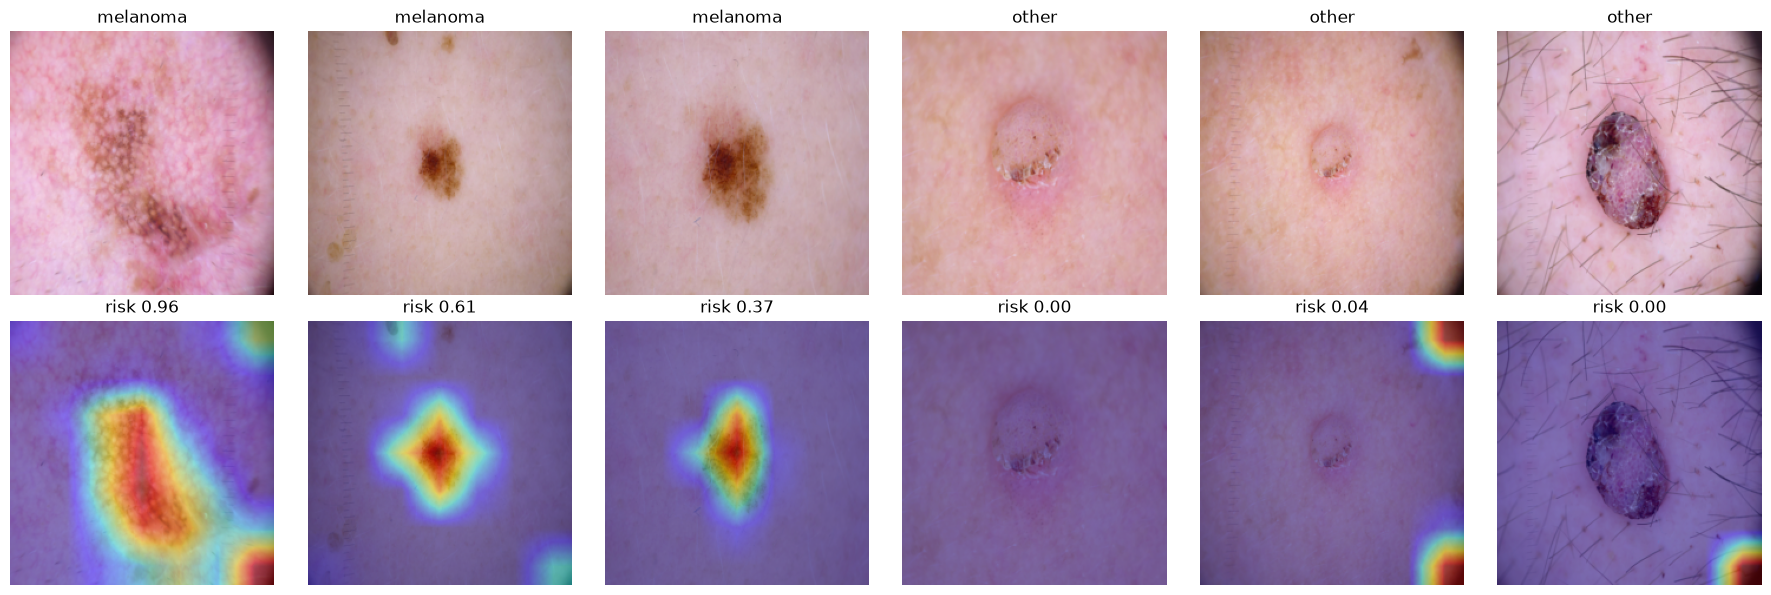

In [10]:
# 6. GRAD-CAM (what the model looked at)
def gradcam(x):
    store = {}
    def hook(m, i, o):
        store["a"] = o
        o.register_hook(lambda g: store.update(g=g))
    h = model.features[-1].register_forward_hook(hook)
    model.eval()
    logit = model(x.unsqueeze(0).to(device).requires_grad_(True))[0, 0]
    model.zero_grad(); logit.backward(); h.remove()
    a, g = store["a"][0].detach(), store["g"][0]
    cam = F.relu((g.mean((1, 2))[:, None, None] * a).sum(0))
    cam = F.interpolate(cam[None, None], size=224, mode="bilinear")[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.cpu().numpy(), torch.sigmoid(logit).item()

ds = DS(test_df, eval_tf())
mel_idx = np.where(test_df.label == 1)[0][:3].tolist() + np.where(test_df.label == 0)[0][:3].tolist()
fig, ax = plt.subplots(2, len(mel_idx), figsize=(3 * len(mel_idx), 6))
for j, i in enumerate(mel_idx):
    x, y = ds[i]
    cam, prob = gradcam(x)
    img = (x * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]).clamp(0, 1).permute(1, 2, 0).numpy()
    ax[0, j].imshow(img); ax[0, j].set_title("melanoma" if y else "other"); ax[0, j].axis("off")
    ax[1, j].imshow(img); ax[1, j].imshow(cam, cmap="jet", alpha=0.45)
    ax[1, j].set_title(f"risk {prob:.2f}"); ax[1, j].axis("off")
plt.tight_layout(); plt.savefig(OUT / "gradcam.png", dpi=130); plt.show()

In [11]:
# 7. EXPORT TO ONNX + INT8 QUANTIZATION (for the Raspberry Pi)
import onnxruntime as ort
from onnxruntime.quantization import quantize_static, CalibrationDataReader, QuantType, QuantFormat

class Export(nn.Module):                      # outputs the risk logit and the last feature map (for the heatmap)
    def __init__(self, m): super().__init__(); self.m = m
    def forward(self, x):
        f = self.m.features(x)
        return self.m.classifier(torch.flatten(self.m.avgpool(f), 1)), f

cpu_model = Export(copy.deepcopy(model).cpu().eval()).eval()
fp32_path, int8_path = OUT / "model_fp32.onnx", OUT / "model_int8.onnx"
kw = dict(input_names=["image"], output_names=["logit", "features"], opset_version=17,
          dynamic_axes={"image": {0: "batch"}, "logit": {0: "batch"}, "features": {0: "batch"}})
try:
    torch.onnx.export(cpu_model, torch.randn(1, 3, 224, 224), str(fp32_path), dynamo=False, **kw)
except TypeError:
    torch.onnx.export(cpu_model, torch.randn(1, 3, 224, 224), str(fp32_path), **kw)

class Calib(CalibrationDataReader):           # 100 training images used to set the INT8 ranges
    def __init__(self):
        d = DS(train_df.sample(min(100, len(train_df)), random_state=0), eval_tf())
        self.it = iter([{"image": d[i][0].unsqueeze(0).numpy()} for i in range(len(d))])
    def get_next(self): return next(self.it, None)

quantize_static(str(fp32_path), str(int8_path), Calib(), quant_format=QuantFormat.QDQ, per_channel=True,
                weight_type=QuantType.QInt8, activation_type=QuantType.QInt8)

def onnx_scores(path):
    sess = ort.InferenceSession(str(path), providers=["CPUExecutionProvider"])
    ys, ps = [], []
    for x, y in test_loader:
        ps.append(1 / (1 + np.exp(-sess.run(None, {"image": x.numpy()})[0][:, 0]))); ys.append(y.numpy())
    return np.concatenate(ys), np.concatenate(ps)

for name, path in [("FP32", fp32_path), ("INT8", int8_path)]:
    y, p = onnx_scores(path)
    print(f"{name}: {path.stat().st_size / 1e6:.1f} MB | {({k: round(float(v), 3) for k, v in report(y, p).items()})}")

# files the Pi needs (model + heatmap weights + threshold)
np.savez(OUT / "head.npz", w=model.classifier[1].weight.detach().cpu().numpy()[0])
json.dump({"threshold": THR}, open(OUT / "threshold.json", "w"))
print("Saved to", OUT.resolve())

C:\Users\naomi\AppData\Local\Temp\ipykernel_41136\3631732514.py:16: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(cpu_model, torch.randn(1, 3, 224, 224), str(fp32_path), dynamo=False, **kw)


FP32: 11.9 MB | {'f1': 0.407, 'precision': 0.261, 'recall': 0.925, 'auc': 0.885, 'sensitivity': 0.925, 'specificity': 0.636, 'accuracy': 0.671}
INT8: 3.4 MB | {'f1': 0.418, 'precision': 0.281, 'recall': 0.812, 'auc': 0.851, 'sensitivity': 0.812, 'specificity': 0.712, 'accuracy': 0.724}
Saved to C:\Users\naomi\OneDrive\Desktop\Career\Projects\MacAI Project\outputs
